# In-Depth Results Analysis — Member 5

This analysis uses the consolidated results from Experiment A (manual prompts), Experiment B (random generation), and Experiment C (genetic algorithm, seeds 42, 7, and 123). It does not rerun the model or any experiment; all values are loaded from `experiments/results/`.

## Research questions
1. Does the best GA prompt outperform the best manual prompt on the validation set?
2. Is there evidence that evolution adds an advantage over the best randomly generated prompt?
3. Are the results consistent across GA seeds?

## Protocol at a glance
- Classifier: Qwen/Qwen2.5-1.5B-Instruct, pinned revision, greedy decoding.
- SST-2: optimization on 1,000 examples; full validation split of 13,468 examples.
- The final test set was not used. Macro-F1 is the primary metric.
- McNemar tests compare paired correct/incorrect predictions on the same examples; they do not directly test a Macro-F1 difference.

Conclusions are limited to these selected prompts, this validation set, this model, and this dataset.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RESULTS_DIR = Path("experiments") / "results"
ROOT = next(
    (candidate for candidate in (Path.cwd(), *Path.cwd().parents)
     if (candidate / RESULTS_DIR / "experiment_C_comparison" / "three_way_comparison.csv").is_file()),
    None,
)
if ROOT is None:
    raise FileNotFoundError(
        "Results not found. Run this notebook from the repository root or one of its subdirectories."
    )

comparison_dir = ROOT / RESULTS_DIR / "experiment_C_comparison"
ga_dir = ROOT / RESULTS_DIR / "genetic_algorithm"
manual_val = pd.read_csv(ROOT / RESULTS_DIR / "experiment_A_manual" / "experiment_A_val_best.csv").iloc[0]
random_val = pd.read_csv(ROOT / RESULTS_DIR / "experiment_B_random" / "experiment_B_val_best.csv").iloc[0]
comparison = pd.read_csv(comparison_dir / "three_way_comparison.csv")
ga_comparison = pd.read_csv(comparison_dir / "ga_multi_seed_comparison.csv")
with (comparison_dir / "mcnemar_tests.json").open(encoding="utf-8") as file:
    mcnemar_results = json.load(file)
with (comparison_dir / "master_experiment_config.json").open(encoding="utf-8") as file:
    experiment_config = json.load(file)
with (ga_dir / "multi_seed_summary.json").open(encoding="utf-8") as file:
    ga_summary = json.load(file)

assert len(comparison) == 3, "The A/B/C comparison table must contain exactly three rows."
assert experiment_config["test_set_used"] is False, "The protocol unexpectedly indicates test-set usage."
assert experiment_config["n_val_examples"] == 13468
manual_comparison = comparison.loc[comparison["experiment"] == "A"].iloc[0]
random_comparison = comparison.loc[comparison["experiment"] == "B"].iloc[0]
assert abs(float(manual_comparison["macro_f1_val"]) - float(manual_val["f1_macro"])) < 1e-6
assert abs(float(random_comparison["macro_f1_val"]) - float(random_val["f1_macro"])) < 1e-6

print(f"Project root: {ROOT}")
print(f"Model: {experiment_config['model_id']}")
print(f"Optimization / validation examples: {experiment_config['n_opt_examples']:,} / {experiment_config['n_val_examples']:,}")
print(f"Test set used: {experiment_config['test_set_used']}")

Project root: C:\Users\DELL\evolutionary-prompt-optimization
Model: Qwen/Qwen2.5-1.5B-Instruct@989aa7980e4cf806f80c7fef2b1adb7bc71aa306
Optimization / validation examples: 1,000 / 13,468
Test set used: False


## 1. Performance and sensitivity to the random seed

The table compares optimization and validation scores. Differences are expressed in **percentage points** (Macro-F1 difference × 100), not relative percentages. Validation results for the three GA seeds are descriptive and were not used to select a seed.

In [2]:
manual = manual_comparison
random_best = random_comparison
ga_seed_rows = {int(row["seed"]): row for _, row in ga_comparison.iterrows()}
ga_invalid_by_seed = {
    seed: int(next(
        row["n_invalid"]
        for row in ga_summary["validation_descriptive"]["rows"]
        if row["prompt_name"] == f"Evolved (seed {seed})"
    ))
    for seed in (42, 7, 123)
}

performance_rows = [
    {
        "Method": "Manual (A)",
        "Seed": "—",
        "Optimization Macro-F1": manual["macro_f1_opt"],
        "Validation Macro-F1": manual["macro_f1_val"],
        "Validation accuracy": manual["accuracy_val"],
        "Invalid validation outputs": int(manual_val["n_invalid"]),
    },
    {
        "Method": "Best random (B)",
        "Seed": "—",
        "Optimization Macro-F1": random_best["macro_f1_opt"],
        "Validation Macro-F1": random_best["macro_f1_val"],
        "Validation accuracy": random_best["accuracy_val"],
        "Invalid validation outputs": int(random_val["n_invalid"]),
    },
]

for seed in (42, 7, 123):
    row = ga_seed_rows[seed]
    performance_rows.append(
        {
            "Method": "Genetic algorithm",
            "Seed": seed,
            "Optimization Macro-F1": row["macro_f1_opt"],
            "Validation Macro-F1": row["macro_f1_val"],
            "Validation accuracy": row["accuracy_val"],
            "Invalid validation outputs": ga_invalid_by_seed[seed],
        }
    )

performance = pd.DataFrame(performance_rows)
manual_f1 = float(manual["macro_f1_val"])
random_f1 = float(random_best["macro_f1_val"])
performance["Difference vs manual (pp)"] = (performance["Validation Macro-F1"] - manual_f1) * 100
performance["Difference vs random (pp)"] = (performance["Validation Macro-F1"] - random_f1) * 100
display(performance.round(4))

ga_validation = performance.loc[performance["Seed"].isin([42, 7, 123]), "Validation Macro-F1"]
print(
    "GA — validation mean: {:.4f}; sample standard deviation: {:.4f}; "
    "range: {:.4f}–{:.4f}".format(
        ga_validation.mean(), ga_validation.std(ddof=1), ga_validation.min(), ga_validation.max()
    )
)
print(
    "Mean GA minus best random: {:+.3f} pp (descriptive, 3 seeds).".format(
        (ga_validation.mean() - random_f1) * 100
    )
)

,Method,Seed,Optimization Macro-F1,Validation Macro-F1,Validation accuracy,Invalid validation outputs,Difference vs manual (pp),Difference vs random (pp)
0,Manual (A),—,0.9364,0.9262,0.9269,0,0.0000,-0.5239
1,Best random (B),—,0.9435,0.9314,0.9321,1,0.5239,0.0000
2,Genetic algorithm,42,0.9434,0.9331,0.9334,13,0.6997,0.1758
3,Genetic algorithm,7,0.9415,0.9254,0.9260,0,-0.0746,-0.5985
4,Genetic algorithm,123,0.9415,0.9271,0.9275,4,0.0921,-0.4318


GA — validation mean: 0.9285; sample standard deviation: 0.0041; range: 0.9254–0.9331
Mean GA minus best random: -0.285 pp (descriptive, 3 seeds).


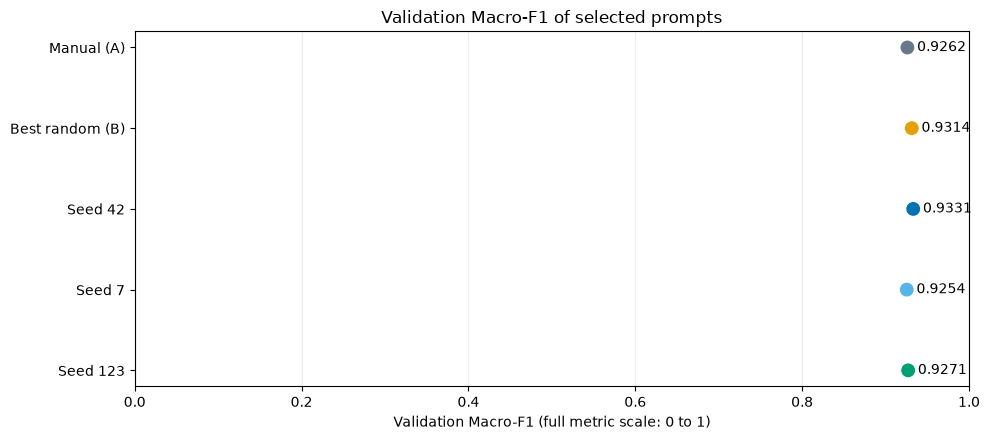

In [3]:
plot_data = performance.copy()
plot_data["Label"] = plot_data.apply(
    lambda row: f"Seed {int(row['Seed'])}" if row["Seed"] != "—" else row["Method"], axis=1
)
colors = ["#68778a", "#e69f00", "#0072b2", "#56b4e9", "#009e73"]
fig, ax = plt.subplots(figsize=(10, 4.5))
scores = plot_data["Validation Macro-F1"].to_numpy()
y_positions = list(range(len(plot_data)))
ax.scatter(scores, y_positions, color=colors, s=80, zorder=3)
for score, y_position in zip(scores, y_positions):
    ax.annotate(f"{score:.4f}", (score, y_position), xytext=(7, 0), textcoords="offset points", va="center")
ax.set_xlim(0, 1)
ax.set_xticks(np.linspace(0, 1, 6))
ax.set_yticks(y_positions, labels=plot_data["Label"])
ax.invert_yaxis()
ax.set_xlabel("Validation Macro-F1 (full metric scale: 0 to 1)")
ax.set_title("Validation Macro-F1 of selected prompts")
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

### Results
- The best GA prompt (seed 42) scores **0.9331** validation Macro-F1, versus **0.9262** for the best manual prompt: about **+0.70 pp**. McNemar supports a difference in paired correctness outcomes; it does not directly test this Macro-F1 difference.
- Against the best random prompt (**0.9314**), seed 42 is ahead by only **+0.18 pp**, and McNemar is not significant. This proves neither equivalence nor a causal advantage from evolution.
- Seeds 7 and 123 score **0.9254** and **0.9271**, respectively, both below the best random prompt. The three-seed GA average is descriptive and below the best random result; seed 42 alone does not establish robustness.
- The best random candidate narrowly leads the GA on `opt` (0.943479 vs 0.943434), but the order reverses on validation. This illustrates sampling uncertainty and selection effects.

## 2. Paired McNemar comparisons

For each pair, discordances count examples where one method is correct and the other is wrong. `b` means method 1 is correct and method 2 is wrong; `c` means the reverse. A positive `c − b` indicates a net advantage in discordant examples for method 2. The Bonferroni adjustment covers the seven comparisons recorded in the results file.

,Comparison (method 1 vs 2),Examples,"b: M1 correct, M2 wrong","c: M1 wrong, M2 correct",Net discordances favor method 2,Discordant examples,Exact p-value,Bonferroni-adjusted p,Significant after Bonferroni
0,Exp-A (Manual) vs Exp-B (Random),13468,152,222,70,374,0.000347,0.002429,True
1,Exp-A (Manual) vs Exp-C (GA seed 42),13468,148,236,88,384,0.000008,0.000056,True
2,Exp-B (Random) vs Exp-C (GA seed 42),13468,111,129,18,240,0.272457,1.000000,False
3,Exp-A (Manual) vs Exp-C (GA seed 7),13468,185,173,-12,358,0.561053,1.000000,False
4,Exp-B (Random) vs Exp-C (GA seed 7),13468,173,91,-82,264,0.000001,0.000007,True
5,Exp-A (Manual) vs Exp-C (GA seed 123),13468,176,184,8,360,0.712233,1.000000,False
6,Exp-B (Random) vs Exp-C (GA seed 123),13468,161,99,-62,260,0.000145,0.001015,True


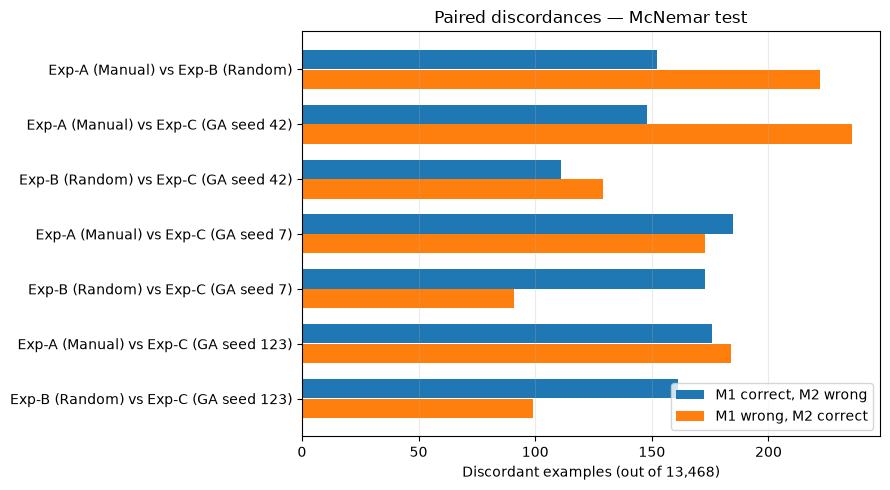

In [4]:
mcnemar = pd.DataFrame(mcnemar_results)
n_tests = len(mcnemar)
mcnemar["Bonferroni-adjusted p"] = (mcnemar["exact_p_value"] * n_tests).clip(upper=1.0)
mcnemar["Net discordances favor method 2"] = (
    mcnemar["c_m1_wrong_m2_right"] - mcnemar["b_m1_right_m2_wrong"]
)
mcnemar["Significant after Bonferroni"] = mcnemar["Bonferroni-adjusted p"] < 0.05
mcnemar_view = mcnemar.rename(
    columns={
        "comparison": "Comparison (method 1 vs 2)",
        "n_examples": "Examples",
        "b_m1_right_m2_wrong": "b: M1 correct, M2 wrong",
        "c_m1_wrong_m2_right": "c: M1 wrong, M2 correct",
        "n_discordant": "Discordant examples",
        "exact_p_value": "Exact p-value",
    }
)[[
    "Comparison (method 1 vs 2)", "Examples",
    "b: M1 correct, M2 wrong", "c: M1 wrong, M2 correct",
    "Net discordances favor method 2", "Discordant examples", "Exact p-value",
    "Bonferroni-adjusted p", "Significant after Bonferroni",
]]
display(mcnemar_view.round(6))

fig, ax = plt.subplots(figsize=(9, 5))
positions = range(len(mcnemar))
ax.barh([p - 0.18 for p in positions], mcnemar["b_m1_right_m2_wrong"], height=0.35, label="M1 correct, M2 wrong")
ax.barh([p + 0.18 for p in positions], mcnemar["c_m1_wrong_m2_right"], height=0.35, label="M1 wrong, M2 correct")
ax.set_yticks(list(positions), labels=mcnemar["comparison"])
ax.invert_yaxis()
ax.set_xlabel("Discordant examples (out of 13,468)")
ax.set_title("Paired discordances — McNemar test")
ax.legend(loc="lower right")
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

### Interpretation and statistical scope
- Manual vs GA seed 42: exact p = **8 × 10⁻⁶**; discordances favor the GA prompt. This remains significant after Bonferroni correction.
- Random vs GA seed 42: exact p ≈ **0.272**; these data do not establish a difference in paired correctness outcomes for these prompts. Non-significance is not evidence of equivalence.
- Random vs GA seeds 7 and 123: discordances favor random; both comparisons remain significant after Bonferroni correction.
- Manual vs GA seeds 7 and 123: neither comparison is significant at the 5% level.

McNemar tests the symmetry of paired correct/incorrect outcomes (closely related to comparing accuracy), not Macro-F1. The tests compare prompts selected using the optimization split, and the seven comparisons are dependent because they reuse methods and prompts. Bonferroni reduces the multiple-testing risk but does not address selection effects or limits to external validity.

## 3. Search budget and validity

The number of text classifications is a proxy for evaluation budget. It does not necessarily capture the full cost of prompt generation or wall-clock runtime.

In [5]:
budget_rows = [
    {
        "Approach": "Manual",
        "Candidates": int(manual["n_candidates"]),
        "Optimization text evaluations": int(manual["opt_text_evals"]),
    },
    {
        "Approach": "Random",
        "Candidates": int(random_best["n_candidates"]),
        "Optimization text evaluations": int(random_best["opt_text_evals"]),
    },
]
for seed in (42, 7, 123):
    row = ga_seed_rows[seed]
    budget_rows.append(
        {
            "Approach": f"GA seed {seed}",
            "Candidates": round(
                int(row["uncached_opt_texts"]) / experiment_config["n_opt_examples"]
            ),
            "Optimization text evaluations": int(row["uncached_opt_texts"]),
        }
    )
display(pd.DataFrame(budget_rows))

,Approach,Candidates,Optimization text evaluations
0,Manual,8,8000
1,Random,50,50000
2,GA seed 42,49,48951
3,GA seed 7,56,55944
4,GA seed 123,59,58941


## 4. Discussion, limitations, and conclusion

### What the results support
On this validation set, the seed-42 GA prompt has a higher Macro-F1 than the best manual prompt. Its paired correctness comparison is significant after the Bonferroni adjustment. However, it does not significantly outperform the best random candidate. The results support finding a strong prompt, but **do not isolate an advantage from evolutionary pressure over unguided generation**.

Seed variability is substantial relative to the GA42–random gap: seed 42 is best on validation, while seeds 7 and 123 are below the random candidate. With only three seeds, the mean and standard deviation are exploratory summaries, not precise estimates of robustness.

### Limitations to state in the report
- **Selection on opt**: the best of 8 manual prompts, 50 random prompts, or a GA population is selected on a 1,000-example sample. Rankings may reflect selection noise (the “winner's curse”).
- **One validation set, model, and corpus**: a single SST-2 split and one pinned Qwen model limit generalization to other corpora, tasks, or models.
- **Three GA seeds**: too few to precisely characterize the performance distribution or identify sources of variance.
- **McNemar**: tests paired correct/incorrect disagreements, not Macro-F1 uncertainty; non-significance is not an equivalence test.
- **Multiple, dependent comparisons**: Bonferroni is applied to the seven reported tests, but comparisons share examples and methods.
- **Incomplete budget accounting**: text evaluations are comparable (GA42: 48,951 vs random: 50,000), but this count alone does not harmonize generation costs or total runtime.
- **Output compliance**: GA42 has 13 invalid outputs out of 13,468 (≈0.097%), compared with 1 for the best random prompt and 0 for manual. The rate is low but should be reported.
- **No final test evaluation**: avoiding test contamination is good practice; the official test score should be evaluated once after the method is frozen.

### Summary
In this controlled experiment, GA seed 42 improves on the best manual prompt by about **0.70 Macro-F1 points**, but its **0.18-point** lead over the best random prompt is not statistically established by McNemar. Seed variability and the weaker results of the other two seeds prevent a conclusion that the genetic algorithm robustly outperforms random generation at a similar evaluation budget. Useful next steps are more independent seeds, full performance and cost distributions, and a single evaluation of the frozen method on an independent test set.

## 5. Additional outputs and unavailable evidence

Saved class-level confusion counts allow stratified individual-metric bootstrap intervals for manual and random, but no paired per-example predictions are available for the GA. Thus no paired Macro-F1 bootstrap comparison or GA confusion matrix is reported. The held-out final test was not used and no test results exist. Crossover/mutation event counts and ablations, and GA token/generation-call totals, were not recorded. These are evidence limitations, not missing fields to fill in.

estimate             bootstrap_ci_95_low              \
method            Manual Random best              Manual Random best   
metric                                                                 
accuracy          0.9269      0.9321              0.9224      0.9278   
macro_f1          0.9262      0.9314              0.9217      0.9271   
macro_precision   0.9250      0.9304              0.9205      0.9260   
macro_recall      0.9279      0.9328              0.9235      0.9286   

                bootstrap_ci_95_high              
method                        Manual Random best  
metric                                            
accuracy                      0.9312      0.9363  
macro_f1                      0.9305      0.9357  
macro_precision               0.9294      0.9347  
macro_recall                  0.9322      0.9370

seed,Seed 7,Seed 42,Seed 123
generation,,,
0,0.9366,0.9406,0.9364
1,0.9366,0.9406,0.9373
2,0.9366,0.9406,0.9375
3,0.9415,0.9434,0.9375
4,0.9415,0.9434,0.9415
5,0.9415,0.9434,0.9415
6,0.9415,0.9434,0.9415
7,0.9415,0.9434,0.9415
8,0.9415,0.9434,0.9415


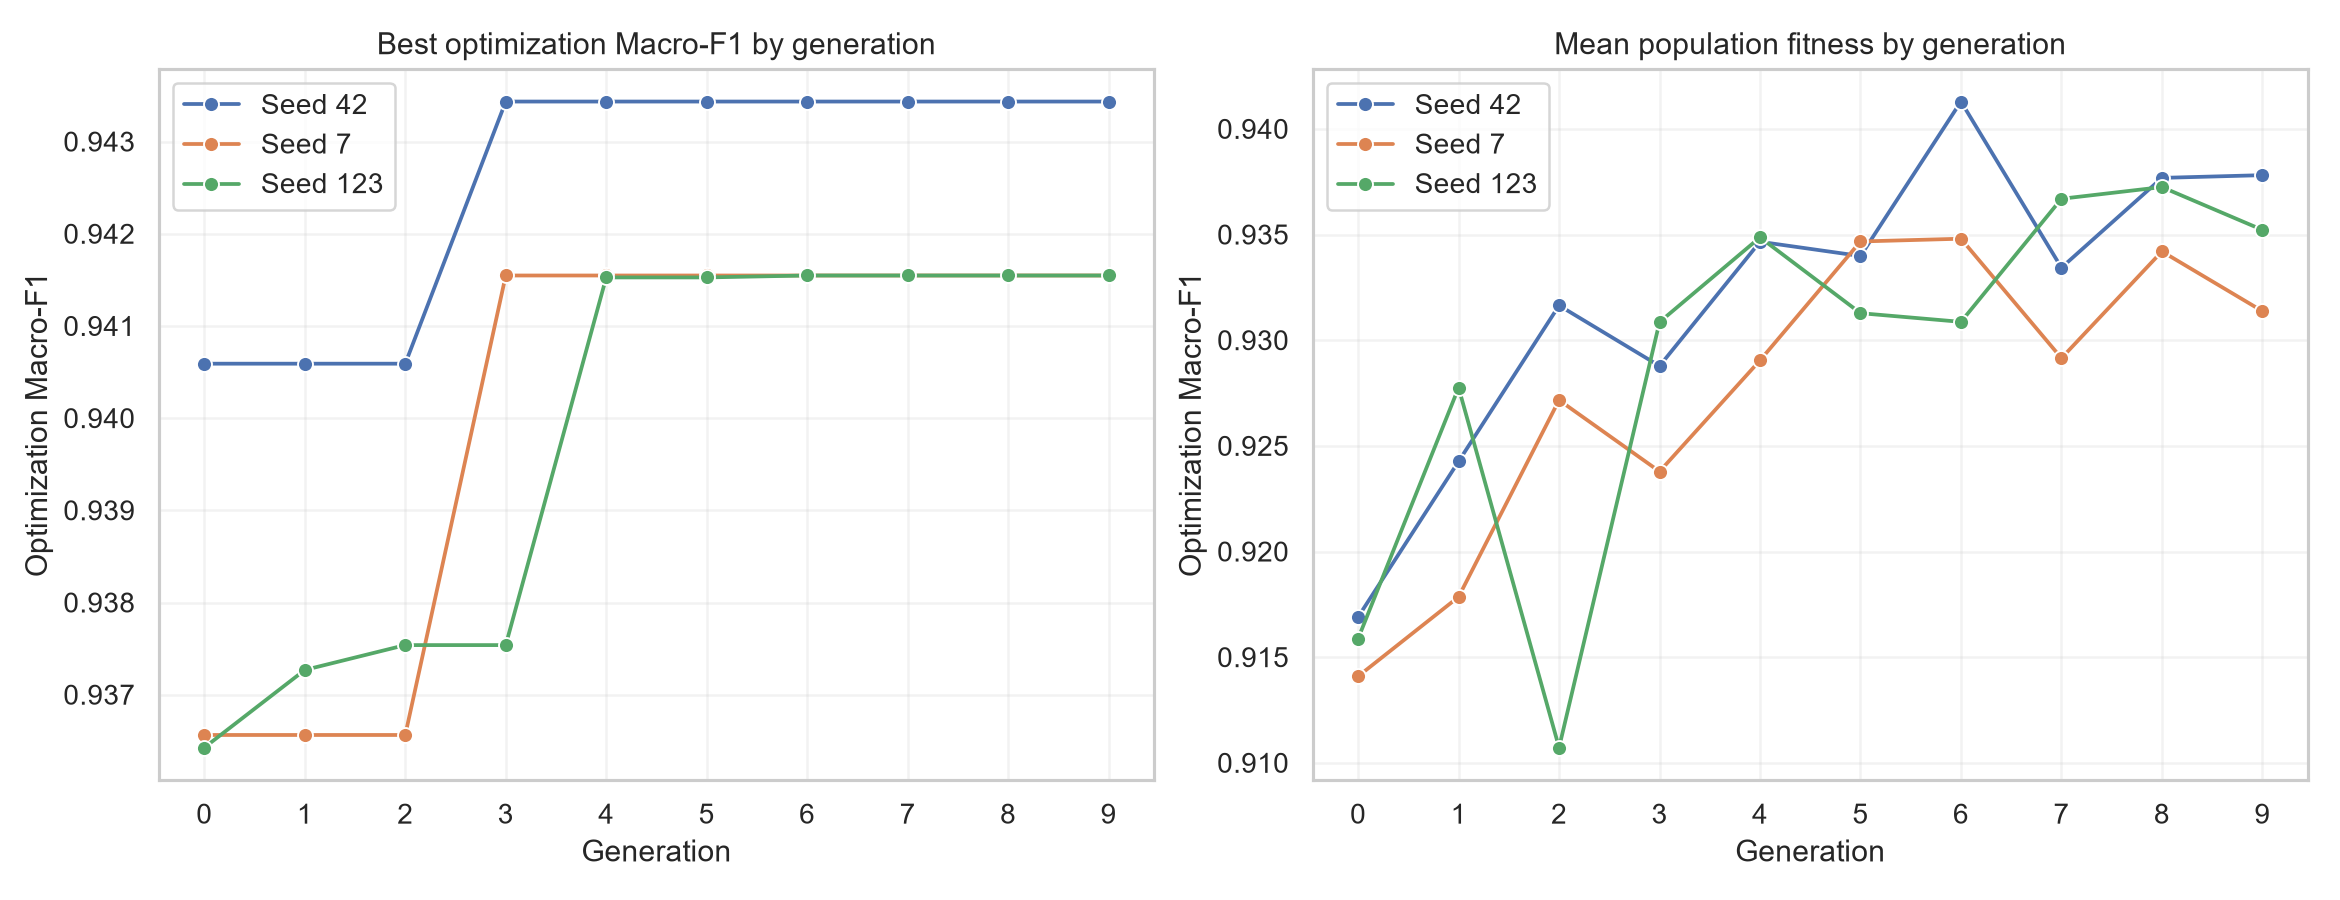

,method,seed,optimization_text_evaluations,reported_runtime_seconds,runtime_scope,prompt_generation_calls,token_count
0,Manual,NaN,8000,278.45,opt + validation wall time,0.0,NaN
1,Random best,NaN,50000,803.94,generation + opt + validation wall time,92.0,NaN
2,Genetic algorithm,42.0,48951,778.41,GA run; phase boundary not separately logged,NaN,NaN
3,Genetic algorithm,7.0,55944,932.42,GA run; phase boundary not separately logged,NaN,NaN
4,Genetic algorithm,123.0,58941,959.11,GA run; phase boundary not separately logged,NaN,NaN


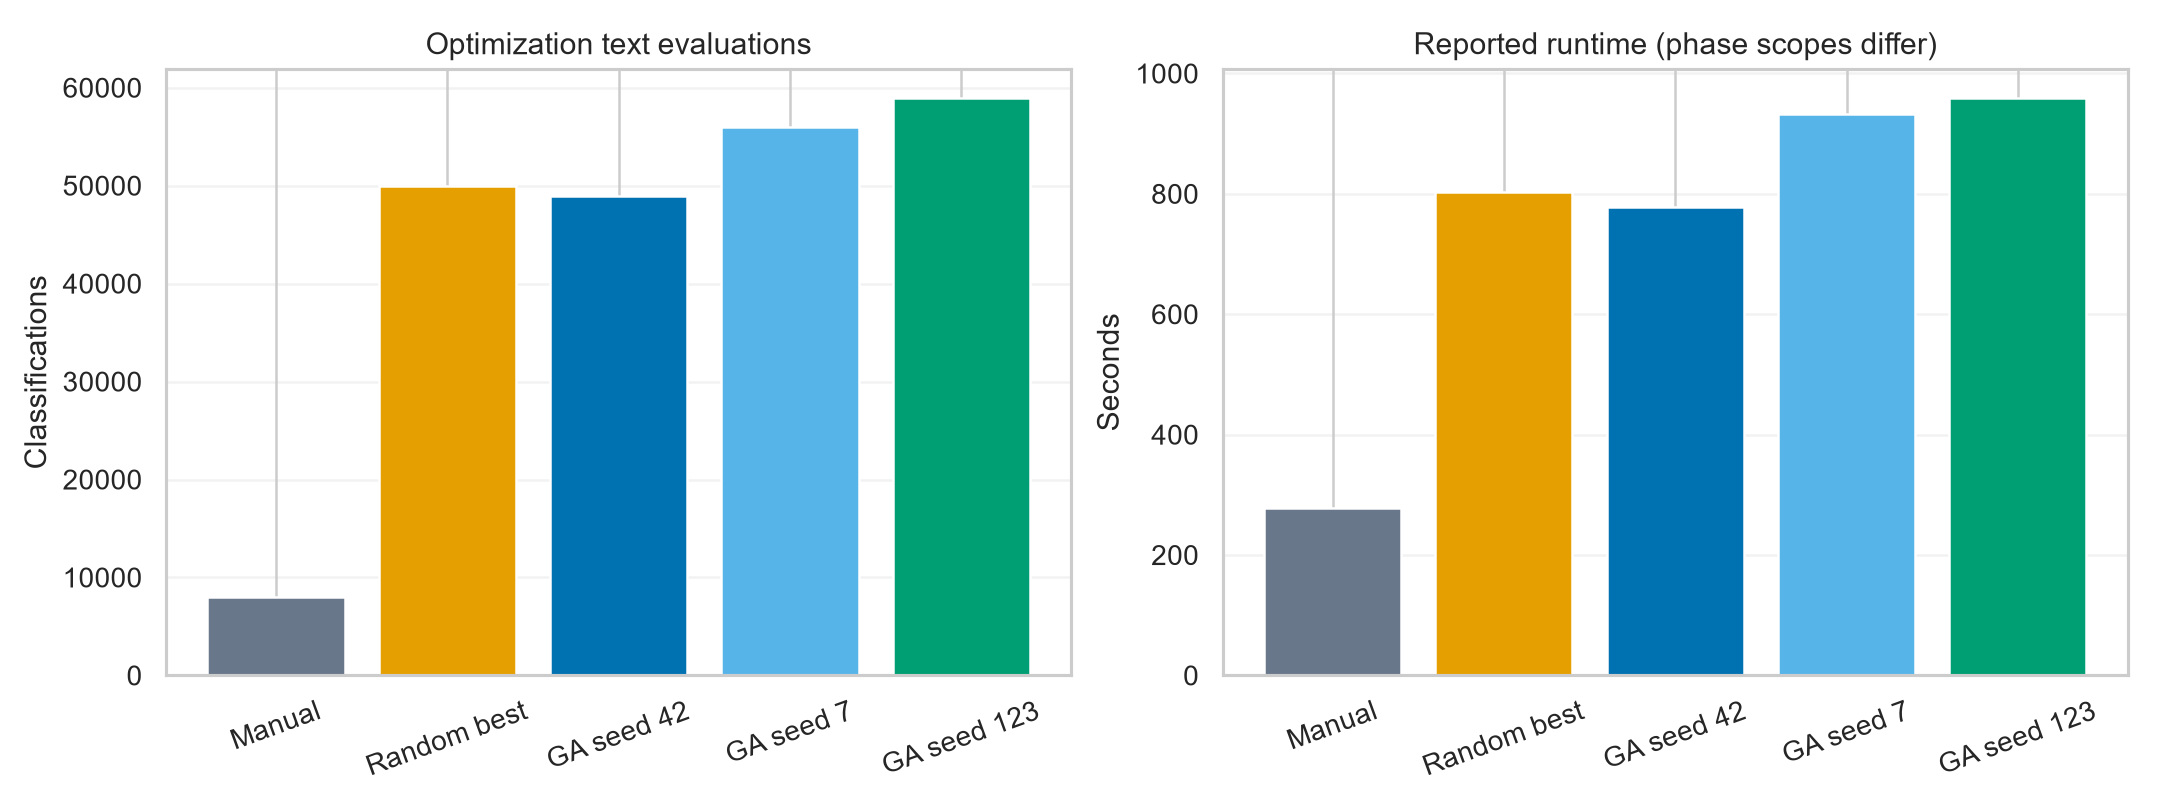

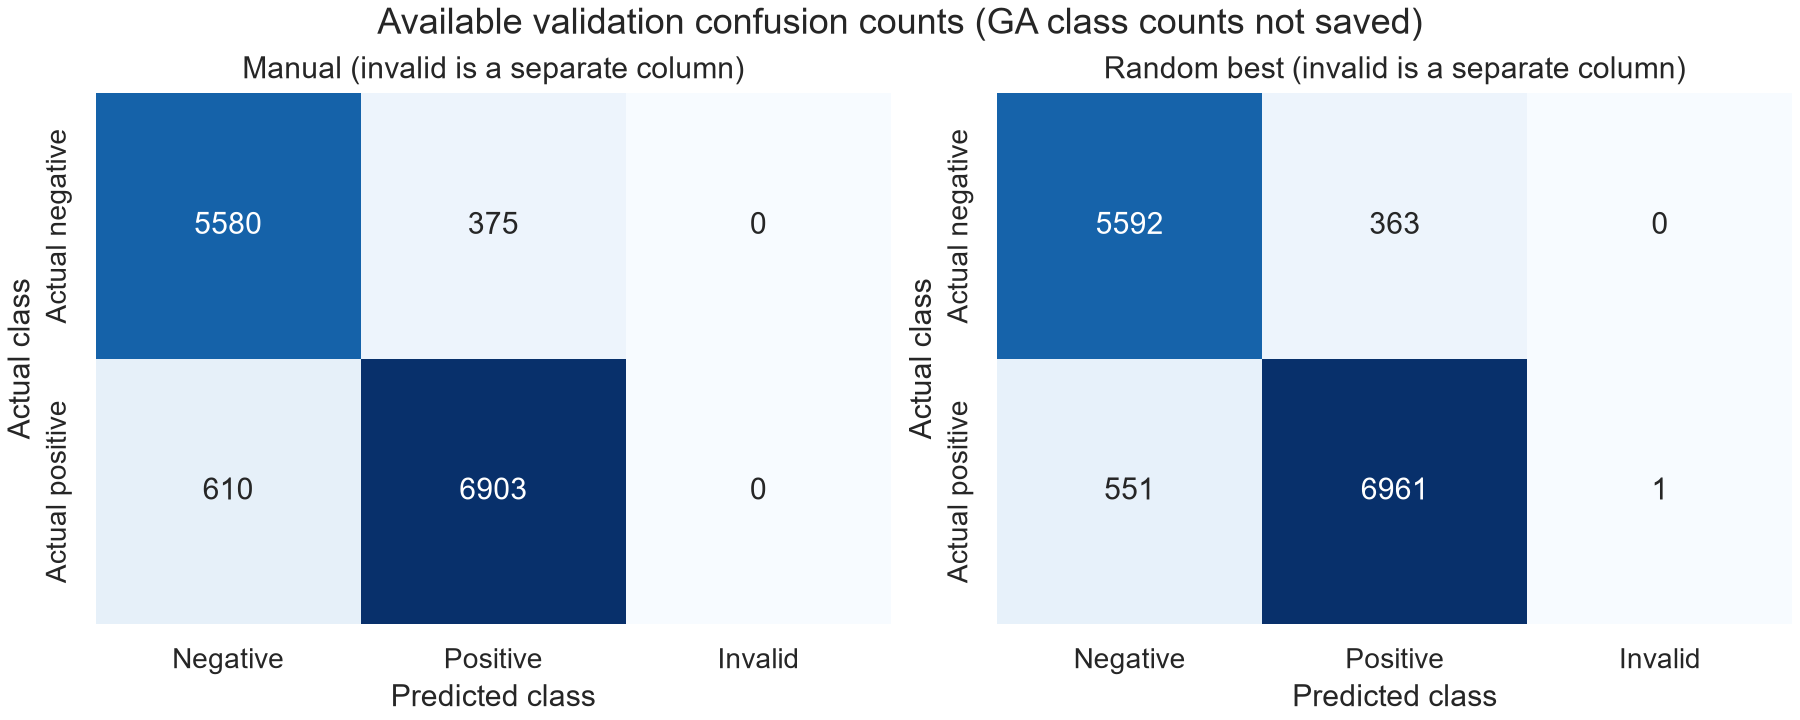

In [6]:
from IPython.display import Image, display
OUTPUT_DIR = ROOT / "experiments" / "results" / "member5_analysis"
bootstrap_ci = pd.read_csv(OUTPUT_DIR / "bootstrap_ci_available_methods.csv")
display(bootstrap_ci.pivot(index="metric", columns="method", values=["estimate", "bootstrap_ci_95_low", "bootstrap_ci_95_high"]).round(4))
generation_metrics = pd.read_csv(OUTPUT_DIR / "ga_generation_metrics.csv")
display(generation_metrics.pivot(index="generation", columns="seed", values="best_fitness").rename(columns=lambda seed: f"Seed {seed}").round(4))
display(Image(filename=str(OUTPUT_DIR / "ga_fitness_by_generation.png")))
cost_table = pd.read_csv(OUTPUT_DIR / "performance_and_cost.csv")
display(cost_table[["method", "seed", "optimization_text_evaluations", "reported_runtime_seconds", "runtime_scope", "prompt_generation_calls", "token_count"]])
display(Image(filename=str(OUTPUT_DIR / "computational_cost.png")))
display(Image(filename=str(OUTPUT_DIR / "available_confusion_matrices.png")))